# Fitur Semantik Dataset Pemodelan: Audit dan Encoding

Notebook ini menyiapkan fitur semantik untuk dataset pemodelan, yaitu dataset yang
sudah melewati filter bahasa dan filter kelengkapan metadata.

Isi notebook dibagi menjadi empat bagian.

Pertama, audit kesiapan dataset: jumlah baris pada setiap tahap, ketersediaan teks
dan metadata, distribusi panjang overview, serta distribusi panjang token.

Kedua, encoding ulang penuh dengan model pretrained yang sama seperti baseline,
lalu penyimpanan artifact ke `artifacts/semantic/`.

Ketiga, verifikasi artifact dan spot check hasil rekomendasi.

Keempat, pembangunan tabel top-K untuk seluruh film, diikuti audit teks yang kembar.

Encoding pada notebook ini adalah inference, bukan training atau fine-tuning.


## 1. Tujuan Audit

Sebelum encoding dijalankan, audit ini menjawab tiga pertanyaan dasar.

Pertama, berapa sebenarnya isi dataset pemodelan, dan bagaimana hubungannya dengan
tahap sebelumnya.

Kedua, apakah seluruh film punya teks dan metadata yang cukup untuk diproses kedua
jalur fitur.

Ketiga, apakah `semantic_text` dataset ini identik dengan teks yang dulu di-encode
pada baseline. Jawaban ini menentukan apakah perbedaan hasil encoding, kalau ada,
berasal dari perubahan data atau dari perubahan model.

Encoding tetap dijalankan dari teks dataset pemodelan, bukan dengan menyalin baris
embedding baseline.


## 2. Perbandingan Dataset pada Setiap Tahap

Lima dataset di project ini mewakili lima tahap yang berbeda.

| Dataset | Jumlah baris | Tahap | Dihasilkan di |
|---|---:|---|---|
| Dataset mentah | 443.610 | Hasil pembacaan CSV | notebook 01 |
| Master dataset | 429.755 | Setelah deduplikasi ID | notebook 01 |
| Baseline eksperimen | 396.254 | Setelah membuang film tanpa teks semantik | notebook 01 |
| Dataset final English-only | 388.241 | Setelah filter bahasa dan overview kosong | notebook 02 |
| Dataset pemodelan | 387.188 | Setelah membuang film tanpa metadata | notebook 01 bagian 13 |

Cell berikut memuat semuanya dan menghitung selisih pada setiap tahap.


In [38]:
import numpy as np
import pandas as pd

from movie_recommender.utils.paths import (
    DATA_RAW_DIR,
    DATA_PROCESSED_DIR,
    SEMANTIC_BASELINE_ARTIFACTS_DIR,
)
raw = pd.read_csv(DATA_RAW_DIR / "TMDB  IMDB Movies Dataset.csv")
final = pd.read_parquet(DATA_PROCESSED_DIR / "movies_modeling.parquet")
baseline = pd.read_parquet(
    DATA_PROCESSED_DIR / "movies_experiment.parquet", columns=["id"]
)
baseline_ids = np.load(
    SEMANTIC_BASELINE_ARTIFACTS_DIR / "movie_ids.npy"
)

print("final shape:", final.shape)
print("raw rows:", len(raw))
print("baseline rows:", len(baseline))
print("baseline embedding rows:", len(baseline_ids))
print("non-english data removed:", len(baseline) - len(final))
print("Count difference (raw - final):", len(raw) - len(final))
print("final ids unique:", final["id"].is_unique)
print("all final ids in baseline:", final["id"].isin(baseline["id"]).all())
print("all final ids have embedding:", final["id"].isin(baseline_ids).all())

final shape: (387188, 31)
raw rows: 443610
baseline rows: 396254
baseline embedding rows: 396254
non-english data removed: 9066
Count difference (raw - final): 56422
final ids unique: True
all final ids in baseline: True
all final ids have embedding: True


Hasil di atas menunjukkan empat hal yang perlu dicatat.

Pertama, dataset pemodelan berisi 387.188 film. Angka ini turun 9.066 dari baseline
396.254.

Kedua, pengurangan 9.066 itu berasal dari dua tahap berbeda. Sebanyak 8.013 film
dibuang di notebook 02 karena overview-nya non-Inggris atau kosong. Sisanya, 1.053
film, dibuang karena keempat kolom metadatanya kosong semua.

Ketiga, seluruh ID dataset pemodelan masih ada di baseline, dan seluruhnya punya
embedding. Artinya tidak ada film yang benar-benar baru, sehingga hasil encoding
ulang bisa dibandingkan baris per baris dengan baseline lama.

Keempat, selisih dari data mentah ke dataset pemodelan adalah 56.422 film, atau
sekitar 12,72 persen. Sebagian besar pengurangan itu terjadi jauh sebelum filter
bahasa, yaitu pada deduplikasi dan pembuangan film tanpa teks semantik.


## 3. Ketersediaan Teks dan Metadata

Dataset final punya aturan keras: seluruh film harus punya overview. Cell berikut memeriksa apakah aturan itu benar-benar berlaku, sekaligus melihat ketersediaan field lain yang nanti dipakai pada pipeline metadata.

Empat kolom teks dan metadata diperiksa dengan definisi yang sama: nilai kosong adalah NaN, string kosong, atau string yang hanya berisi spasi.


In [39]:
text_columns = ["overview", "tagline", "keywords"]
metadata_columns = ["genres", "directors", "writers", "cast"]

for column in text_columns + metadata_columns:
    values = final[column].fillna("").astype(str).str.strip()
    blank = int(values.eq("").sum())
    print(f"{column:12s} blank={blank:7d} ({blank / len(final) * 100:5.2f}%)")

has_metadata = (
    final[metadata_columns]
    .fillna("")
    .astype(str)
    .apply(lambda series: series.str.strip().ne(""))
    .any(axis=1)
)

print()
print("punya minimal satu metadata:", int(has_metadata.sum()))
print("tanpa metadata sama sekali:", int((~has_metadata).sum()))

overview     blank=      0 ( 0.00%)
tagline      blank= 296828 (76.66%)
keywords     blank= 224896 (58.08%)
genres       blank=  64514 (16.66%)
directors    blank=   7961 ( 2.06%)
writers      blank=  58707 (15.16%)
cast         blank=  59210 (15.29%)

punya minimal satu metadata: 387188
tanpa metadata sama sekali: 0


Beberapa angka yang perlu diperhatikan.

`overview` kosong sebanyak nol baris. Ini konsekuensi aturan di notebook 02, yang
membuang film dengan overview kosong.

`tagline` kosong di 76,66 persen film. Artinya sebagian besar `semantic_text`
sebenarnya tidak memuat tagline, dan hanya bersumber dari overview, kadang ditambah
keywords.

`keywords` kosong di 58,08 persen film. Bersama tagline, ini menjelaskan kenapa
separuh dataset hanya punya overview sebagai bahan embedding.

Di sisi metadata, `genres` kosong di 16,66 persen film. Ini kolom metadata dengan
tingkat kekosongan tertinggi, dan akan memengaruhi kualitas jalur metadata.

Film tanpa metadata sama sekali sekarang nol. Ini berbeda dari dataset final, yang
masih punya 1.053 film tanpa metadata. Film-film itu sudah dibuang pada tahap
finalisasi, sehingga tidak ada lagi vektor metadata bernorma nol pada dataset ini.


## 4. Kombinasi Field yang Membentuk semantic_text

`semantic_text` dibentuk dari tiga field dengan aturan: field yang kosong dilewati. Karena overview selalu ada, bagian `Overview:` selalu muncul.

Cell berikut menghitung berapa film yang hanya punya overview, berapa yang punya kombinasi dua field, dan berapa yang lengkap.


In [40]:
overview = final["overview"].fillna("").astype(str).str.strip().ne("")
tagline = final["tagline"].fillna("").astype(str).str.strip().ne("")
keywords = final["keywords"].fillna("").astype(str).str.strip().ne("")

print("overview saja            :", int((~tagline & ~keywords).sum()))
print("overview + tagline       :", int((tagline & ~keywords).sum()))
print("overview + keywords      :", int((~tagline & keywords).sum()))
print("overview + tagline + kw  :", int((tagline & keywords).sum()))

overview saja            : 192901
overview + tagline       : 31995
overview + keywords      : 103927
overview + tagline + kw  : 58365


Sebanyak 192.901 film, atau 49,8 persen, hanya memiliki overview sebagai sumber teks
semantik.

Sisanya mendapat tambahan dari keywords (103.927 film), tagline (31.995 film), atau
keduanya (58.365 film).

Angka ini berguna untuk membahas keterbatasan di Bab IV. Untuk separuh dataset,
kualitas embedding sepenuhnya bergantung pada sinopsis. Kalau sinopsisnya pendek
atau generik, representasinya juga terbatas.


## 5. Distribusi Panjang Overview

Bagian ini melihat panjang overview dalam karakter dan kata. Tujuannya memahami karakteristik data, bukan memutuskan truncation. Keputusan truncation ditentukan oleh jumlah token, yang dihitung pada bagian berikutnya.

Beberapa istilah yang dipakai:

| Istilah | Arti |
|---|---|
| p50 (median) | Nilai tengah. Setengah film punya nilai di bawah ini, setengah di atas |
| p90 | 90 persen film punya nilai di bawah atau sama dengan angka ini |
| max | Nilai terbesar di seluruh dataset |
| mean | Rata-rata, mudah terpengaruh nilai ekstrem |

Median dan p90 lebih menggambarkan kondisi umum dibanding rata-rata, terutama pada distribusi yang miring.


In [41]:
overview_text = final["overview"].fillna("").astype(str).str.strip()
char_counts = overview_text.str.len()
word_counts = overview_text.str.split().str.len()

print("karakter  p50=%d p90=%d max=%d" % (
    char_counts.quantile(0.50),
    char_counts.quantile(0.90),
    char_counts.max(),
))
print("kata      p50=%d mean=%.1f max=%d" % (
    word_counts.quantile(0.50),
    word_counts.mean(),
    word_counts.max(),
))

karakter  p50=226 p90=573 max=1000
kata      p50=39 mean=48.4 max=203


Median overview adalah 226 karakter atau sekitar 39 kata. Angka ini menggambarkan
film tipikal: ringkas, sekitar dua sampai tiga kalimat.

Rata-rata jumlah kata adalah 48,4, lebih besar daripada median 39. Selisih ini muncul
karena sebagian kecil overview sangat panjang dan menarik rata-rata ke atas. Inilah
yang disebut distribusi miring ke kanan.

Nilai maksimum 1000 karakter terlihat mencurigakan karena angkanya bulat. Kemungkinan
besar itu batas dari sumber data, bukan panjang alami teks film tersebut. Artinya
overview terpanjang pun mungkin sudah dipotong sebelum masuk ke pipeline ini. Ini
berbeda dari truncation model dan perlu dibedakan saat menulis metodologi.


## 6. Panjang Token dan Batas Model

Panjang overview dalam karakter tidak menentukan apakah teks terpotong. Yang menentukan adalah jumlah token dibanding `max_seq_length` model.

Panjang token diambil dari artifact `token_lengths.parquet`, yang sudah dihitung sebelumnya untuk baseline. Pengambilan dilakukan per ID agar urutannya mengikuti dataset final.


In [42]:
token_lengths = (
    pd.read_parquet(SEMANTIC_BASELINE_ARTIFACTS_DIR / "token_lengths.parquet")
    .set_index("id")["token_length"]
)

subset_tokens = token_lengths.loc[final["id"]]

print("teks diukur:", len(subset_tokens))
print("p50=%d p90=%d p95=%d p99=%d max=%d" % (
    subset_tokens.quantile(0.50),
    subset_tokens.quantile(0.90),
    subset_tokens.quantile(0.95),
    subset_tokens.quantile(0.99),
    subset_tokens.max(),
))
print("di atas 250 token:", int(subset_tokens.gt(250).sum()))
print("di atas 512 token:", int(subset_tokens.gt(512).sum()))
print("max_seq_length   :", 512)

teks diukur: 387188
p50=62 p90=140 p95=168 p99=214 max=370
di atas 250 token: 356
di atas 512 token: 0
max_seq_length   : 512


Hasilnya menunjukkan median 62 token, p90 140 token, dan maksimum 370 token.

Batas model adalah 512 token. Karena nilai maksimum hanya 370, tidak ada satu pun teks
yang melewati batas. Jumlah film dengan token di atas 512 adalah nol.

Sebanyak 356 film melewati 250 token. Angka 250 bukan batas keras model, melainkan
panjang teks yang disebut pada model card sebagai rentang saat training. Film di atas
250 tetap di-encode utuh karena masih di bawah 512.

Dibandingkan baseline yang punya maksimum 782 token dan 16 teks terpotong, dataset ini
jauh lebih aman. Teks terpanjang di baseline ternyata berasal dari overview berbahasa
non-Inggris yang sekarang sudah dibuang.


## 7. Visualisasi Distribusi Panjang

Tiga grafik berikut menjawab tiga pertanyaan berbeda:

1. berapa panjang overview film tipikal,
2. seberapa jauh distribusi token dari batas model,
3. bagaimana hubungan jumlah kata dan jumlah token.

Grafik pertama memakai jumlah kata, bukan token, karena tujuannya menggambarkan karakteristik teks dari sudut pandang pembaca.


In [43]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from movie_recommender.utils.paths import (
    DATA_PROCESSED_DIR,
    SEMANTIC_BASELINE_ARTIFACTS_DIR,
)

final = pd.read_parquet(
    DATA_PROCESSED_DIR / "movies_modeling.parquet",
    columns=["id", "overview"],
)

token_lengths = (
    pd.read_parquet(SEMANTIC_BASELINE_ARTIFACTS_DIR / "token_lengths.parquet")
    .set_index("id")["token_length"]
    .loc[final["id"]]
)

word_counts = final["overview"].fillna("").astype(str).str.split().str.len()

print("films:", len(final))
print("token p50/p90/p99/max:", int(token_lengths.quantile(0.50)),
      int(token_lengths.quantile(0.90)),
      int(token_lengths.quantile(0.99)),
      int(token_lengths.max()))

films: 387188
token p50/p90/p99/max: 62 140 214 370


Cell berikut memuat ulang `final` dengan hanya kolom `id` dan `overview`. Ini dilakukan untuk menghemat memori saat membuat grafik.

Konsekuensinya, variabel `final` pada sel setelah ini tidak lagi memuat kolom `semantic_text`. Kalau nanti membutuhkan kolom lain, muat ulang dengan daftar kolom yang sesuai.


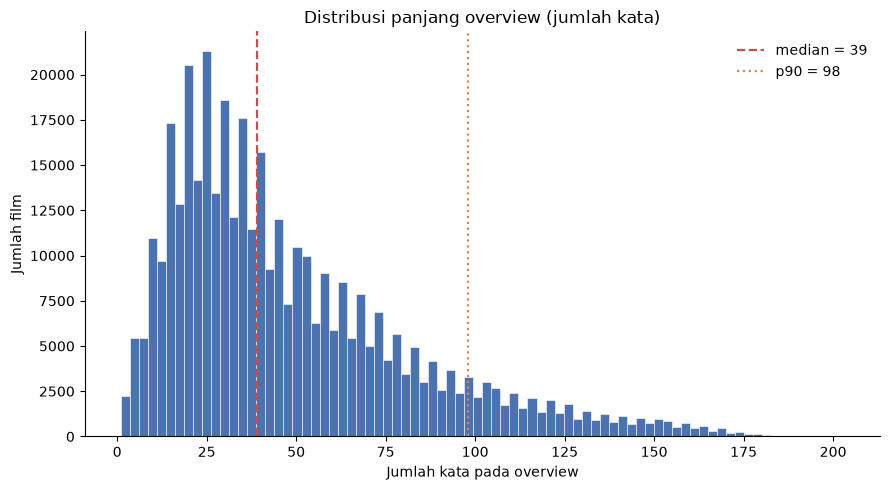

In [44]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(word_counts, bins=80, color="#4C72B0", edgecolor="white", linewidth=0.4)
ax.axvline(word_counts.median(), color="#C44E52", linestyle="--", linewidth=1.6,
           label=f"median = {int(word_counts.median())}")
ax.axvline(word_counts.quantile(0.90), color="#DD8452", linestyle=":", linewidth=1.6,
           label=f"p90 = {int(word_counts.quantile(0.90))}")

ax.set_xlabel("Jumlah kata pada overview")
ax.set_ylabel("Jumlah film")
ax.set_title("Distribusi panjang overview (jumlah kata)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

Grafik pertama menunjukkan bentuk distribusi yang miring ke kanan. Puncaknya berada di sekitar 20 sampai 40 kata, lalu ekor panjang ke arah kanan. Garis median dan p90 membantu menunjukkan posisi film tipikal dan batas 90 persen data.


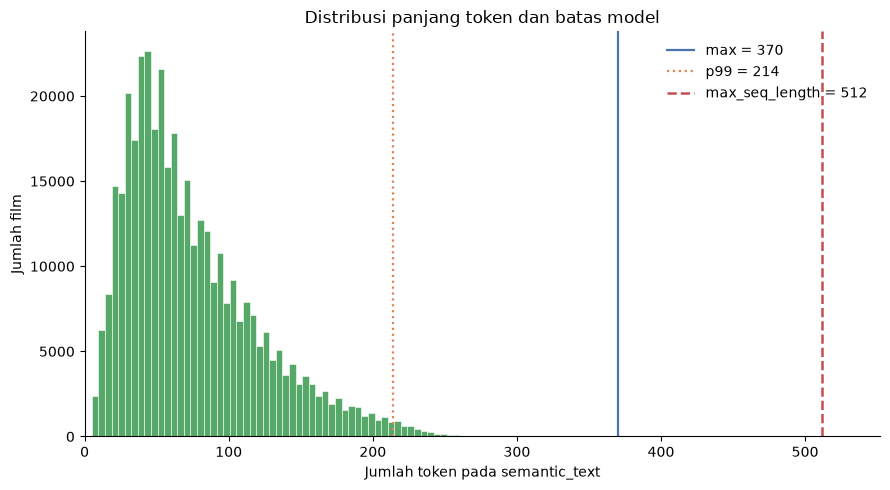

film melewati 512 token: 0


In [45]:
MAX_SEQ_LENGTH = 512

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(token_lengths, bins=80, color="#55A868", edgecolor="white", linewidth=0.4)
ax.axvline(token_lengths.max(), color="#4C72B0", linestyle="-", linewidth=1.6,
          label=f"max = {int(token_lengths.max())}")
ax.axvline(token_lengths.quantile(0.99), color="#DD8452", linestyle=":", linewidth=1.6,
          label=f"p99 = {int(token_lengths.quantile(0.99))}")
ax.axvline(MAX_SEQ_LENGTH, color="#C44E52", linestyle="--", linewidth=1.8,
          label=f"max_seq_length = {MAX_SEQ_LENGTH}")

ax.set_xlim(0, MAX_SEQ_LENGTH + 40)
ax.set_xlabel("Jumlah token pada semantic_text")
ax.set_ylabel("Jumlah film")
ax.set_title("Distribusi panjang token dan batas model")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

print("film melewati 512 token:", int(token_lengths.gt(MAX_SEQ_LENGTH).sum()))

Grafik kedua adalah yang paling penting untuk keputusan teknis. Garis putus-putus adalah batas model 512 token.

Seluruh batang histogram berhenti jauh sebelum garis tersebut. Ini bukti visual bahwa tidak ada teks yang terpotong pada dataset final, dan keputusan mempertahankan `max_seq_length` 512 tidak menimbulkan kehilangan informasi.


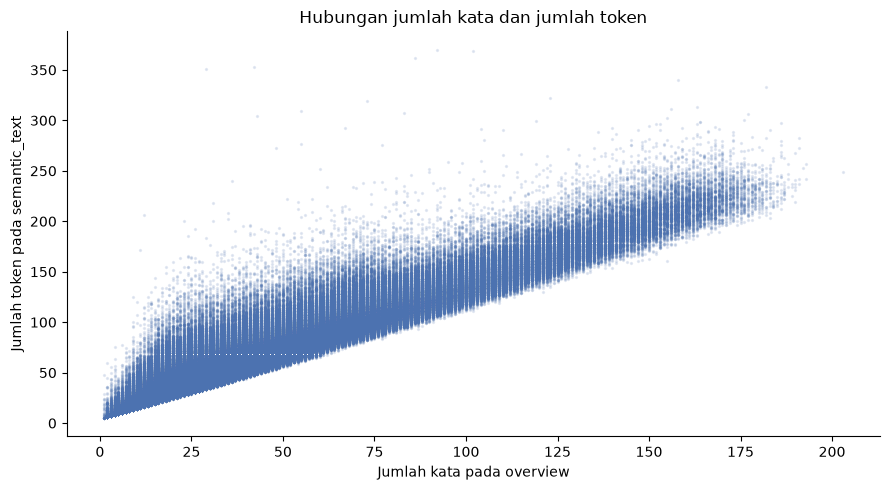

In [46]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(word_counts, token_lengths, s=2, alpha=0.12, color="#4C72B0", rasterized=True)

ax.set_xlabel("Jumlah kata pada overview")
ax.set_ylabel("Jumlah token pada semantic_text")
ax.set_title("Hubungan jumlah kata dan jumlah token")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

Grafik ketiga menunjukkan hubungan jumlah kata dengan jumlah token. Hubungannya naik, tetapi tidak lurus sempurna.

Ada dua penyebab. Pertama, `semantic_text` juga memuat tagline dan keywords, sehingga dua film dengan jumlah kata overview sama bisa punya jumlah token berbeda. Kedua, tokenisasi memecah kata asing atau nama diri menjadi beberapa token, sehingga rasio token terhadap kata tidak tetap.


## 8. Menyimpan Grafik untuk Skripsi

Grafik distribusi token disimpan ke `results/figures/` dengan resolusi 300 dpi. Resolusi ini cukup untuk dicetak, dan `bbox_inches="tight"` memotong margin yang tidak perlu.


In [47]:
from movie_recommender.utils.paths import RESULTS_DIR

figures_dir = RESULTS_DIR / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# Ulangi salah satu grafik sebelum save, misalnya token distribution
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(token_lengths, bins=80, color="#55A868", edgecolor="white", linewidth=0.4)
ax.axvline(MAX_SEQ_LENGTH, color="#C44E52", linestyle="--", linewidth=1.8,
            label=f"max_seq_length = {MAX_SEQ_LENGTH}")
ax.set_xlim(0, MAX_SEQ_LENGTH + 40)
ax.set_xlabel("Jumlah token pada semantic_text")
ax.set_ylabel("Jumlah film")
ax.set_title("Distribusi panjang token dan batas model")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)

fig.savefig(figures_dir / "token_distribution.png", dpi=300, bbox_inches="tight")
plt.close(fig)

print("saved:", figures_dir / "token_distribution.png")

saved: D:\College Life\Skripsiw\hybrid-movie-recommender\results\figures\token_distribution.png


Setelah gambar disimpan, figure ditutup dengan `plt.close`. Ini mencegah penumpukan objek gambar di memori ketika notebook dijalankan berulang.


In [48]:
token_lengths = (
    pd.read_parquet(SEMANTIC_BASELINE_ARTIFACTS_DIR / "token_lengths.parquet")
    .set_index("id")["token_length"]
)

subset_tokens = token_lengths.loc[final["id"]]

print("teks diukur:", len(subset_tokens))
print("p50=%d p90=%d p95=%d p99=%d max=%d" % (
    subset_tokens.quantile(0.50),
    subset_tokens.quantile(0.90),
    subset_tokens.quantile(0.95),
    subset_tokens.quantile(0.99),
    subset_tokens.max(),
))
print("di atas 250 token:", int(subset_tokens.gt(250).sum()))
print("di atas 512 token:", int(subset_tokens.gt(512).sum()))
print("max_seq_length   :", 512)

teks diukur: 387188
p50=62 p90=140 p95=168 p99=214 max=370
di atas 250 token: 356
di atas 512 token: 0
max_seq_length   : 512


## 9. Pemeriksaan Kesamaan semantic_text

Ini pemeriksaan inti sebelum encoding ulang dijalankan.

Kalau `semantic_text` untuk seluruh film dataset pemodelan identik dengan teks yang
dulu di-encode pada baseline, maka encoding ulang seharusnya menghasilkan vektor yang
setara. Pemeriksaan ini juga memastikan filter bahasa dan filter metadata hanya
membuang baris, tidak menyunting teks film yang lolos.

Kalau ada teks yang berbeda, perbedaan hasil encoding nanti bukan bug, melainkan
konsekuensi dari perubahan input. Saat itu terjadi, perbedaan tersebut harus
dilaporkan.


In [49]:
baseline_text = (
    pd.read_parquet(SEMANTIC_BASELINE_ARTIFACTS_DIR / "semantic_text.parquet")
    .set_index("id")["semantic_text"]
)

final_text = pd.read_parquet(
    DATA_PROCESSED_DIR / "movies_modeling.parquet",
    columns=["id", "semantic_text"],
).set_index("id")["semantic_text"]

expected = baseline_text.loc[final["id"]].to_numpy()
actual = final_text.loc[final["id"]].to_numpy()

print("baris dibandingkan:", len(expected))
print("identik:", bool(np.array_equal(expected, actual)))
print("berbeda:", int((expected != actual).sum()))

baris dibandingkan: 387188
identik: True
berbeda: 0


Hasilnya: 387.188 baris dibandingkan, seluruhnya identik, nol baris berbeda.

Ini berarti filter bahasa dan filter metadata hanya membuang baris, tidak menyunting
teks film yang lolos. Konsekuensinya, encoding ulang memakai input yang sama dengan
baseline untuk film yang sama, sehingga hasilnya nanti bisa dibandingkan secara
langsung.

Kalau nanti aturan filter diubah, misalnya tagline dan keywords juga difilter, hasil
pemeriksaan ini kemungkinan berubah menjadi tidak identik. Saat itu terjadi, perbedaan
hasil encoding adalah hal yang wajar dan perlu dicatat.


## 10. Ringkasan Angka untuk Dokumentasi

Cell berikut merangkum angka utama ke dalam satu Series agar mudah disalin ke `docs/experiment_log.md` dan Bab IV.


In [50]:
summary = {
    "rows": len(final),
    "removed_from_raw": len(raw) - len(final),
    "percentage_of_removed_data": (len(raw) - len(final))/len(raw) * 100,
    "removed_from_baseline": len(baseline) - len(final),
    "overview_blank": int(final["overview"].fillna("").astype(str).str.strip().eq("").sum()),
    "semantic_text_identical_to_baseline": bool(np.array_equal(expected, actual)),
    "token_max": int(subset_tokens.max()),
    "token_over_512": int(subset_tokens.gt(512).sum()),
    "films_without_any_metadata": int((~has_metadata).sum()),
}

pd.Series(summary, name="value")

rows                                     387188
removed_from_raw                          56422
percentage_of_removed_data             12.71883
removed_from_baseline                      9066
overview_blank                                0
semantic_text_identical_to_baseline        True
token_max                                   370
token_over_512                                0
films_without_any_metadata                    0
Name: value, dtype: object

### Ringkasan Dataset Pemodelan

Dataset pemodelan berisi 387.188 film, turun 9.066 dari baseline 396.254.

Seluruh film memiliki overview, sehingga tidak ada `semantic_text` yang kosong.

Teks dataset ini identik dengan baseline untuk ID yang sama, sehingga encoding ulang
memakai input yang setara dan hasilnya bisa dibandingkan secara langsung.

Panjang token maksimum adalah 370, jauh di bawah `max_seq_length` 512. Tidak ada satu
pun teks yang mengalami truncation.

Berbeda dari dataset final, tidak ada lagi film tanpa metadata pada dataset ini,
karena 1.053 film tersebut sudah dibuang pada tahap finalisasi.

Sebanyak 192.901 film hanya memiliki overview sebagai sumber teks semantik.


## 11. Encoding Ulang Penuh

Bagian ini membangun embedding dari teks dataset pemodelan, tanpa mengambil baris dari
embedding baseline. Tujuannya memastikan pipeline tidak bergantung pada artifact lama
dan menyediakan bukti independen bahwa hasil encoding konsisten.

Model, teks, dan `max_seq_length` sama dengan baseline. Karena itu encoding ini bukan
perbaikan kualitas, melainkan pembangunan ulang representasi untuk populasi yang sudah
dibersihkan.

Hasil disimpan ke `artifacts/semantic/`, sedangkan baseline 396.254 film tetap berada
di `artifacts/semantic_baseline/` dan tidak ditimpa.

Encoding penuh membutuhkan sekitar 21 sampai 22 menit pada RTX 3050 dengan batch size
32. Flag `RUN_ENCODE` disetel `False` karena artifact sudah terbentuk. Setel `True`
hanya ketika ingin membangun ulang dari nol.


In [51]:
import json
import time
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import sentence_transformers
import torch
from sentence_transformers import SentenceTransformer

from movie_recommender.features.sbert import encode_semantic_texts
from movie_recommender.utils.paths import (
    DATA_PROCESSED_DIR,
    SEMANTIC_ARTIFACTS_DIR,
)

MODEL_NAME = "sentence-transformers/multi-qa-distilbert-cos-v1"
OUTPUT_DIR = SEMANTIC_ARTIFACTS_DIR
BATCH_SIZE = 32
TOKEN_BATCH_SIZE = 2048

# Set True untuk menjalankan encoding penuh, False untuk melewati.
RUN_ENCODE = False

# Frame CSV mentah hanya dipakai di bagian audit. Dilepas di sini agar RAM
# tersedia untuk matriks embedding selama encoding.
if "raw" in globals():
    del raw

# 1. Load dan validasi input
frame = pd.read_parquet(
    DATA_PROCESSED_DIR / "movies_modeling.parquet",
    columns=["id", "semantic_text"],
).reset_index(drop=True)

if not frame["id"].is_unique:
    raise ValueError("Movie IDs tidak unik")
if frame["id"].isna().any():
    raise ValueError("Ada movie ID kosong")

texts = frame["semantic_text"].fillna("")
if texts.str.strip().eq("").any():
    raise ValueError("Ada semantic_text kosong")

print("film:", len(frame))
print("teks:", len(texts))

# 2. Load model
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

model = SentenceTransformer(MODEL_NAME, device=device)
max_seq_length = model.max_seq_length
print("model:", MODEL_NAME)
print("max_seq_length:", max_seq_length)

# 3. Audit token tanpa truncation
tokenizer = model[0].tokenizer
lengths = []
for start in range(0, len(texts), TOKEN_BATCH_SIZE):
    batch = texts.iloc[start:start + TOKEN_BATCH_SIZE].tolist()
    encoded = tokenizer(
        batch,
        add_special_tokens=True,
        truncation=False,
        padding=False,
    )
    lengths.extend(len(ids) for ids in encoded["input_ids"])

token_lengths = pd.Series(lengths, index=texts.index, name="token_length")
print("token max:", int(token_lengths.max()))
print("di atas 512:", int(token_lengths.gt(max_seq_length).sum()))

# 4. Encode
if not RUN_ENCODE:
    print("RUN_ENCODE = False, encoding dilewati")
else:
    if device == "cuda":
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()

    start_time = time.perf_counter()
    embeddings = encode_semantic_texts(
        model=model,
        texts=texts,
        batch_size=BATCH_SIZE,
    )
    if device == "cuda":
        torch.cuda.synchronize()
    elapsed_seconds = time.perf_counter() - start_time

    # 5. Simpan artifact
    movie_ids = frame["id"].to_numpy(dtype=np.int64)
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    np.save(OUTPUT_DIR / "embeddings.npy", embeddings)
    np.save(OUTPUT_DIR / "movie_ids.npy", movie_ids)

    pd.DataFrame(
        {
            "id": movie_ids,
            "semantic_text": pd.array(texts.to_numpy(), dtype="string"),
        }
    ).to_parquet(
        OUTPUT_DIR / "semantic_text.parquet",
        index=False,
        compression="zstd",
    )

    pd.DataFrame(
        {
            "id": movie_ids,
            "token_length": token_lengths.to_numpy(),
        }
    ).to_parquet(
        OUTPUT_DIR / "token_lengths.parquet",
        index=False,
        compression="zstd",
    )

    config = {
        "build_method": "full_reencode",
        "input_dataset": "data/processed/movies_modeling.parquet",
        "model_name": MODEL_NAME,
        "embedding_dim": int(embeddings.shape[1]),
        "dtype": str(embeddings.dtype),
        "n_texts": int(embeddings.shape[0]),
        "n_movies": int(len(frame)),
        "max_seq_length": int(max_seq_length),
        "batch_size": BATCH_SIZE,
        "device": str(model.device),
        "truncation": "model default (max_seq_length)",
        "n_over_250_tokens": int(token_lengths.gt(250).sum()),
        "n_over_512_tokens": int(token_lengths.gt(max_seq_length).sum()),
        "token_max": int(token_lengths.max()),
        "elapsed_seconds": round(elapsed_seconds, 2),
        "peak_gpu_memory_mib": (
            round(torch.cuda.max_memory_allocated() / 1024**2, 1)
            if device == "cuda"
            else 0.0
        ),
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "sentence_transformers_version": sentence_transformers.__version__,
        "torch_version": torch.__version__,
        "numpy_version": np.__version__,
        "pandas_version": pd.__version__,
    }
    (OUTPUT_DIR / "config.json").write_text(
        json.dumps(config, indent=2),
        encoding="utf-8",
    )

    print("embedding shape:", embeddings.shape)
    print("embedding dtype:", embeddings.dtype)
    print("waktu encoding:", round(elapsed_seconds, 2), "detik")

film: 387188
teks: 387188
device: cuda


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

model: sentence-transformers/multi-qa-distilbert-cos-v1
max_seq_length: 512
token max: 370
di atas 512: 0
RUN_ENCODE = False, encoding dilewati


In [52]:
config

{'build_method': 'full_reencode',
 'input_dataset': 'data/processed/movies_modeling.parquet',
 'model_name': 'sentence-transformers/multi-qa-distilbert-cos-v1',
 'embedding_dim': 768,
 'dtype': 'float32',
 'n_texts': 387188,
 'n_movies': 387188,
 'max_seq_length': 512,
 'batch_size': 32,
 'device': 'cuda:0',
 'truncation': 'model default (max_seq_length)',
 'n_over_250_tokens': 356,
 'n_over_512_tokens': 0,
 'token_max': 370,
 'elapsed_seconds': 1291.82,
 'peak_gpu_memory_mib': 640.2,
 'created_at_utc': '2026-11-21T19:33:11.505943+00:00',
 'sentence_transformers_version': '6.2.0',
 'torch_version': '2.15.0+cu134',
 'numpy_version': '2.4.6',
 'pandas_version': '3.1.1'}

## 12. Verifikasi Artifact

Verifikasi membaca kembali file dari disk, bukan memakai variabel di memori. Tujuannya
memastikan artifact yang tersimpan benar-benar dapat dipakai pada tahap berikutnya.

Pemeriksaan mencakup bentuk matriks, tipe data, jumlah baris, keunikan ID, kesamaan
urutan ID dengan dataset pemodelan, kesamaan teks, kesamaan panjang token, nilai
finite, dan norma vektor.

Baris yang paling penting adalah kesamaan urutan ID. Kalau urutan berbeda, penggabungan
metadata dan embedding berdasarkan posisi baris akan salah, dan kesalahannya sulit
dilacak setelah hasil rekomendasi keluar.


In [53]:
import json

import numpy as np
import pandas as pd

from movie_recommender.utils.paths import (
    DATA_PROCESSED_DIR,
    SEMANTIC_ARTIFACTS_DIR,
)

if not (SEMANTIC_ARTIFACTS_DIR / "embeddings.npy").exists():
    raise FileNotFoundError(
        f"Artifact belum ada di {SEMANTIC_ARTIFACTS_DIR}. "
        "Jalankan cell encoding dengan RUN_ENCODE = True lebih dulu."
    )

embeddings_check = np.load(
    SEMANTIC_ARTIFACTS_DIR / "embeddings.npy",
    mmap_mode="r",
)
ids_check = np.load(SEMANTIC_ARTIFACTS_DIR / "movie_ids.npy")
text_check = pd.read_parquet(
    SEMANTIC_ARTIFACTS_DIR / "semantic_text.parquet"
)
token_check = pd.read_parquet(
    SEMANTIC_ARTIFACTS_DIR / "token_lengths.parquet"
)
config_check = json.loads(
    (SEMANTIC_ARTIFACTS_DIR / "config.json").read_text(encoding="utf-8")
)

final_source = pd.read_parquet(
    DATA_PROCESSED_DIR / "movies_modeling.parquet",
    columns=["id", "semantic_text"],
)

norms = np.linalg.norm(embeddings_check[:1000], axis=1)

checks = {
    "shape": embeddings_check.shape,
    "dtype": str(embeddings_check.dtype),
    "rows sama dengan movie_ids": embeddings_check.shape[0] == len(ids_check),
    "rows sama dengan movies_modeling": embeddings_check.shape[0] == len(final_source),
    "movie_ids unik": len(np.unique(ids_check)) == len(ids_check),
    "urutan ID sama dengan movies_modeling": bool(
        np.array_equal(ids_check, final_source["id"].to_numpy())
    ),
    "semantic_text sama dengan movies_modeling": bool(
        np.array_equal(
            text_check["semantic_text"].to_numpy(),
            final_source["semantic_text"].fillna("").to_numpy(),
        )
    ),
    "token_length sama dengan movies_modeling": len(token_check) == len(final_source),
    "embedding finite": bool(np.isfinite(embeddings_check[:1000]).all()),
    "norm minimum": float(norms.min()),
    "norm maksimum": float(norms.max()),
    "embedding_dim sesuai config": (
        config_check["embedding_dim"] == embeddings_check.shape[1]
    ),
    "n_texts sesuai config": (
        config_check["n_texts"] == embeddings_check.shape[0]
    ),
}

key_checks_passed = (
    checks["rows sama dengan movies_modeling"]
    and checks["movie_ids unik"]
    and checks["urutan ID sama dengan movies_modeling"]
    and checks["semantic_text sama dengan movies_modeling"]
    and checks["embedding finite"]
    and checks["n_texts sesuai config"]
)

print("semua pemeriksaan kunci lulus:", bool(key_checks_passed))

pd.Series(checks, name="value")

semua pemeriksaan kunci lulus: True


shape                                        (387188, 768)
dtype                                              float32
rows sama dengan movie_ids                            True
rows sama dengan movies_modeling                      True
movie_ids unik                                        True
urutan ID sama dengan movies_modeling                 True
semantic_text sama dengan movies_modeling             True
token_length sama dengan movies_modeling              True
embedding finite                                      True
norm minimum                                           1.0
norm maksimum                                          1.0
embedding_dim sesuai config                           True
n_texts sesuai config                                 True
Name: value, dtype: object

## 13. Spot Check Embedding

Verifikasi sebelumnya memeriksa bentuk dan urutan. Bagian ini memeriksa isi: apakah
tetangga terdekat setiap film masih masuk akal setelah populasi dataset berubah.

Lima film dipakai sebagai sampel, dan untuk masing-masing diambil tiga tetangga
terdekat. Kalau hasilnya masih konsisten dengan pemeriksaan pada dataset sebelumnya,
berarti encoding dan alignment bekerja dengan benar.

Nilai similarity tidak berubah dibanding dataset final, karena film yang dibuang
bukan tetangga terdekat dari kelima sampel ini.


In [54]:
import numpy as np
import pandas as pd

from movie_recommender.utils.paths import DATA_PROCESSED_DIR, SEMANTIC_ARTIFACTS_DIR

embeddings = np.load(SEMANTIC_ARTIFACTS_DIR / "embeddings.npy")
movie_ids = np.load(SEMANTIC_ARTIFACTS_DIR / "movie_ids.npy")

movies = pd.read_parquet(
    DATA_PROCESSED_DIR / "movies_modeling.parquet",
    columns=["id", "title", "genres"],
).set_index("id")

row_of = pd.Series(np.arange(len(movie_ids)), index=movie_ids)

SPOT_CHECKS = [27205, 157336, 155, 862, 603]

for query_id in SPOT_CHECKS:
    if query_id not in row_of.index:
        print(query_id, "tidak ada di dataset baru")
        continue

    row = int(row_of.loc[query_id])
    scores = embeddings @ embeddings[row]
    scores[row] = -np.inf

    top_rows = np.argpartition(scores, -3)[-3:]
    top_rows = top_rows[np.argsort(scores[top_rows])[::-1]]

    print("=" * 70)
    print(f"QUERY: {movies.loc[query_id, 'title']}")
    for r in top_rows:
        print(f"  {scores[r]:.4f} | {movies.loc[movie_ids[r], 'title']}")

QUERY: Inception
  0.5609 | Respect the Jux
  0.5494 | American Psycho
  0.5439 | Vivegam
QUERY: Interstellar
  0.6550 | The Beyond
  0.6533 | Beachworld
  0.6320 | In Space with Markiplier: Part 2
QUERY: The Dark Knight
  0.6963 | The Dark Knight Rises
  0.6961 | The Batman
  0.6954 | Batman: Mask of the Phantasm
QUERY: Toy Story
  0.7221 | Toy Story 3
  0.6951 | Toy Story 2
  0.6688 | Toy Story 4
QUERY: The Matrix
  0.6753 | The Matrix Resurrections
  0.6471 | The Matrix Revisited
  0.6467 | The Animatrix


### Ringkasan Encoding

Artifact dataset pemodelan berada di `artifacts/semantic/` dengan 387.188 baris dan
768 dimensi, bertipe `float32`. Urutan baris mengikuti `movies_modeling.parquet`.

Waktu encoding tercatat 1.291,82 detik, sekitar 21,5 menit, dengan peak VRAM 640,2
MiB pada batch size 32.

Baseline 396.254 film tetap tersimpan di `artifacts/semantic_baseline/`. Keduanya
dibangun dari model dan teks yang sama, sehingga hasilnya setara dan dapat dipakai
sebagai pembanding pada pembahasan.

Encoding pada notebook ini adalah inference, bukan training atau fine-tuning.


## 14. Query Top-K Langsung dari Embedding

Bagian ini menguji hasil rekomendasi secara langsung dari matriks embedding yang baru
dibangun. Tujuannya bukan evaluasi formal, melainkan pemeriksaan kewajaran: apakah film
yang mirip secara tema benar-benar muncul berdekatan.

Mekanismenya sederhana. Setiap film sudah diwakili satu vektor 768 dimensi. Untuk satu
film query, dihitung cosine similarity terhadap seluruh 387.188 film, lalu diambil K
nilai terbesar.

Dua hal teknis yang perlu dipahami sebelum membaca hasilnya.

Pertama, cosine similarity dihitung sebagai dot product biasa, karena embedding sudah
dinormalisasi L2 saat encoding. Norma setiap vektor sekitar 1, sehingga dot product
langsung menghasilkan nilai cosine.

Kedua, film query harus dikeluarkan dari kandidat. Tanpa langkah itu, rank 1 setiap
query akan selalu film itu sendiri dengan similarity 1,0. Caranya dengan mengisi skor
film query menjadi negatif tak hingga.


Cell berikut memuat embedding dan metadata film. Embedding dibaca penuh ke RAM, bukan
memakai `mmap`, karena seluruh matriks dipakai berulang untuk beberapa query. Ukurannya
sekitar 1,19 GB.

Perhatikan bahwa variabel `movies` di sini hanya memuat enam kolom. Kolom `overview`
tidak dimuat. Kalau nanti membutuhkan overview, muat ulang dengan daftar kolom yang
sesuai.

Baris pemeriksaan terakhir adalah yang paling penting. Kalau `embedding cocok dengan
dataset` bernilai `False`, urutan baris embedding tidak sejajar dengan dataset, dan
semua hasil query akan salah. Jangan lanjutkan kalau nilainya `False`.


In [55]:
import numpy as np
import pandas as pd
import torch

from movie_recommender.utils.paths import DATA_PROCESSED_DIR, SEMANTIC_ARTIFACTS_DIR

embeddings = np.load(SEMANTIC_ARTIFACTS_DIR / "embeddings.npy")
movie_ids = np.load(SEMANTIC_ARTIFACTS_DIR / "movie_ids.npy")

movies = pd.read_parquet(
    DATA_PROCESSED_DIR / "movies_modeling.parquet",
    columns=["id", "title", "release_date", "genres", "directors", "vote_average"],
).set_index("id")

print("embeddings:", embeddings.shape, embeddings.dtype)
print("movie_ids:", movie_ids.shape)
print("film unik:", movies.index.is_unique)
print("embedding cocok dengan dataset:", np.array_equal(movie_ids, movies.index.to_numpy()))

embeddings: (387188, 768) float32
movie_ids: (387188,)
film unik: True
embedding cocok dengan dataset: True


Cell berikut menjalankan empat film sebagai query. Pemilihannya disengaja agar mewakili
karakter berbeda: satu science fiction, satu space epic, satu superhero, dan satu
animasi.

Empat film ini hanya contoh. Hasil untuk seluruh 387.188 film dihitung pada bagian
berikutnya.


In [56]:
QUERY_IDS = [27205, 157336, 155, 862]
K = 10

ids_index = pd.Series(np.arange(len(movie_ids)), index=movie_ids)

for query_id in QUERY_IDS:
    row = int(ids_index.loc[query_id])

    scores = embeddings @ embeddings[row]
    scores[row] = -np.inf

    top_rows = np.argsort(scores)[::-1][:K]
    top_ids = movie_ids[top_rows]

    result = movies.loc[top_ids, ["title", "genres", "vote_average"]].copy()
    result.insert(0, "rank", range(1, K + 1))
    result["similarity"] = scores[top_rows].round(4)

    print("=" * 88)
    print(f"QUERY: {movies.loc[query_id, 'title']} | id={query_id}")
    print(result[["rank", "title", "similarity"]].to_string(index=False))
    print()

QUERY: Inception | id=27205
 rank                        title  similarity
    1              Respect the Jux      0.5609
    2              American Psycho      0.5494
    3                      Vivegam      0.5439
    4          The Hunter's Prayer      0.5378
    5                       Gultoo      0.5367
    6                       Parker      0.5256
    7                         ECCO      0.5197
    8               No Sudden Move      0.5163
    9 Making a Deal with the Devil      0.5163
   10                 Strange Days      0.5152

QUERY: Interstellar | id=157336
 rank                            title  similarity
    1                       The Beyond      0.6550
    2                       Beachworld      0.6533
    3 In Space with Markiplier: Part 2      0.6320
    4                      Time Runner      0.6254
    5                             Tomb      0.6166
    6                       Prometheus      0.6094
    7                  Space Explorers      0.5578
    8         

Pola yang muncul dari empat query di atas perlu dibaca dengan hati-hati, karena tidak
semuanya menunjukkan hal yang sama.

**Franchise tertangkap sangat kuat.** The Dark Knight menghasilkan sepuluh film Batman.
Toy Story menghasilkan tiga sekuel resmi pada tiga peringkat teratas. Ini terjadi karena
judul seri dan nama karakter muncul berulang di `overview` dan `keywords`.

**Tema besar juga tertangkap.** Interstellar menghasilkan film luar angkasa, dan
Spirited Away menghasilkan film animasi Jepang termasuk Totoro. Ini kemiripan tema,
bukan sekadar kemiripan kata.

**Sebagian hasil justru menunjukkan kelemahan.** Model cenderung tertarik pada kesamaan
kata, bukan kesamaan makna. Contohnya Toy Story menarik kartun lama bernama "Woody The
Freeloader", karena kata "Woody" muncul di kedua teks. Fenomena ini disebut lexical
attraction, dan sering muncul pada teks pendek.

**Rentang skor sempit.** Semua similarity berada di kisaran 0,51 sampai 0,72. Selisih
antara rank 1 dan rank 10 biasanya hanya sekitar 0,04. Artinya pemisahan antar kandidat
lemah, sehingga perubahan kecil pada skor bisa mengubah urutan.

Temuan ini bukan kegagalan yang perlu disembunyikan. Justru inilah alasan penelitian
menggabungkan fitur teks dengan fitur metadata.


## 15. Membangun Tabel Top-K untuk Seluruh Film

Bagian ini menghitung rekomendasi untuk semua 387.188 film, bukan hanya beberapa contoh.

Ada satu batasan yang harus dipahami lebih dulu. Menghitung seluruh pasangan film
sekaligus berarti matriks berukuran 387.188 x 387.188, yaitu sekitar 1,5 x 10^11 angka.
Dalam `float32`, itu setara sekitar 559 GB. Angka tersebut tidak muat di RAM 15,6 GB,
tidak muat di VRAM 4 GB, dan bahkan tidak muat di sisa ruang disk.

Karena itu perhitungan dilakukan per blok. Setiap blok berisi 256 film query. Untuk satu
blok, dihitung skor 256 x 387.188, yaitu sekitar 378 MB. Dari situ hanya diambil 10
teratas per film, lalu sisanya dibuang. Proses diulang sampai seluruh film terpakai.

Konsekuensinya, hasil akhir hanya berisi 3.871.880 baris, yaitu sekitar 0,0026 persen
dari seluruh pasangan. Inilah yang membuat pekerjaan ini layak dilakukan pada mesin
dengan RAM terbatas.


Cell berikut menulis file mentah berisi empat kolom saja: `query_movie_id`, `rank`,
`recommended_movie_id`, dan `similarity`. Penulisan dilakukan bertahap dengan mode
append, jadi file tidak pernah ditahan penuh di memori.

Perhatikan baris `del scores, top_scores, top_index, frame`. Tanpa itu, PyTorch menahan
cache memori antar blok, dan VRAM bisa habis di tengah proses meskipun setiap blok
sebenarnya kecil.

Flag `RUN_BUILD_TOP10` disetel `False` karena file sudah terbentuk. Setel `True` hanya
ketika ingin membangun ulang. Perhatikan bahwa cabang `True` menghapus file lama lebih
dulu, jadi proses tidak bisa dilanjutkan dari tengah.

Estimasi waktu sekitar 5 sampai 20 menit pada GPU. Kalau nilai `device` yang tercetak
adalah `cpu`, prosesnya bisa jauh lebih lama.


In [57]:
import time

from movie_recommender.utils.paths import RESULTS_DIR

# Set True hanya ketika ingin menghitung ulang seluruh tabel top-K.
# False mencegah Run All mengulang proses 5 sampai 20 menit.
RUN_BUILD_TOP10 = False

K = 10
BLOCK_SIZE = 256

output_path = RESULTS_DIR / "recommendations" / "semantic_all_top10_raw.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)

EXPECTED_ROWS = len(movie_ids) * K

if not RUN_BUILD_TOP10:
    print("RUN_BUILD_TOP10 = False, pembangunan tabel top-K dilewati")

    if output_path.exists():
        print("file sudah ada:", output_path)
        print("ukuran MB:", round(output_path.stat().st_size / 1024**2, 1))
        print("baris yang diharapkan:", EXPECTED_ROWS)
    else:
        print("file belum ada:", output_path)
        print("set RUN_BUILD_TOP10 = True untuk membangunnya")
        print("tanpa file ini, bagian 16 dan 17 akan gagal")
else:
    if output_path.exists():
        output_path.unlink()

    device = "cuda" if torch.cuda.is_available() else "cpu"
    print("device:", device)

    matrix = torch.from_numpy(embeddings).to(device)
    n_movies = matrix.shape[0]

    start_time = time.perf_counter()
    header_written = False

    for start in range(0, n_movies, BLOCK_SIZE):
        stop = min(start + BLOCK_SIZE, n_movies)
        block = matrix[start:stop]

        scores = block @ matrix.T

        local_rows = torch.arange(stop - start, device=device)
        global_cols = torch.arange(start, stop, device=device)
        scores[local_rows, global_cols] = float("-inf")

        top_scores, top_index = torch.topk(scores, K, dim=1)

        frame = pd.DataFrame(
            {
                "query_movie_id": np.repeat(movie_ids[start:stop], K),
                "rank": np.tile(np.arange(1, K + 1), stop - start),
                "recommended_movie_id": movie_ids[top_index.cpu().numpy().ravel()],
                "similarity": top_scores.cpu().numpy().ravel().astype(np.float32),
            }
        )
        frame.to_csv(
            output_path,
            mode="w" if not header_written else "a",
            header=not header_written,
            index=False,
        )
        header_written = True

        del scores, top_scores, top_index, frame
        if stop % (BLOCK_SIZE * 40) == 0:
            elapsed = time.perf_counter() - start_time
            print(f"{stop}/{n_movies} | {elapsed:.0f} detik")

    torch.cuda.empty_cache()
    print("selesai:", round(time.perf_counter() - start_time, 1), "detik")
    print("file:", output_path)
    print("ukuran MB:", round(output_path.stat().st_size / 1024**2, 1))
    print("baris seharusnya:", EXPECTED_ROWS)

RUN_BUILD_TOP10 = False, pembangunan tabel top-K dilewati
file sudah ada: D:\College Life\Skripsiw\hybrid-movie-recommender\results\recommendations\semantic_all_top10_raw.csv
ukuran MB: 101.0
baris yang diharapkan: 3871880


File mentah tadi hanya berisi ID, sehingga belum bisa dibaca manusia. Cell berikut
menggabungkan hasil tersebut dengan judul, genre, sutradara, rating, dan tanggal rilis
dari dataset pemodelan.

Penggabungan dilakukan dua kali: sekali untuk sisi query, sekali untuk sisi rekomendasi.
Keduanya memakai `how="left"` agar tidak ada baris yang hilang kalau sebuah ID tidak
ditemukan.

Hasilnya disimpan dengan `encoding="utf-8-sig"`. Pengaturan ini menambahkan penanda byte
order mark di awal file, supaya karakter non-ASCII seperti e dengan aksen tetap terbaca
benar ketika dibuka di Excel.

Satu peringatan: file hasilnya berukuran sekitar 451 MB dengan 3,87 juta baris. Jangan
membukanya di Excel, karena aplikasi itu akan kehabisan memori. Gunakan pandas atau
aplikasi khusus seperti DB Browser for SQLite.

Flag `RUN_MERGE_TOP10` disetel `False` karena file gabungan sudah terbentuk.


In [58]:
# Set True hanya ketika ingin membangun ulang CSV gabungan.
RUN_MERGE_TOP10 = True

raw_path = RESULTS_DIR / "recommendations" / "semantic_all_top10_raw.csv"
final_path = RESULTS_DIR / "recommendations" / "semantic_all_top10.csv"

if not RUN_MERGE_TOP10:
    print("RUN_MERGE_TOP10 = False, penggabungan dilewati")
    if final_path.exists():
        print("file sudah ada:", final_path)
        print("ukuran MB:", round(final_path.stat().st_size / 1024**2, 1))
    else:
        print("file belum ada:", final_path)
        print("set RUN_MERGE_TOP10 = True untuk membangunnya")
else:
    if not raw_path.exists():
        raise FileNotFoundError(
            f"File mentah belum ada: {raw_path}. "
            "Jalankan cell top-K dengan RUN_BUILD_TOP10 = True lebih dulu."
        )

    pairs = pd.read_csv(raw_path)

    query_info = movies.reset_index().rename(
        columns={
            "id": "query_movie_id",
            "title": "query_title",
            "genres": "query_genres",
        }
    )[["query_movie_id", "query_title", "query_genres"]]

    rec_info = movies.reset_index().rename(
        columns={
            "id": "recommended_movie_id",
            "title": "recommended_title",
            "genres": "recommended_genres",
            "directors": "recommended_directors",
            "vote_average": "recommended_vote_average",
            "release_date": "recommended_release_date",
        }
    )

    result = (
        pairs
        .merge(query_info, on="query_movie_id", how="left")
        .merge(rec_info, on="recommended_movie_id", how="left")
    )

    result.to_csv(final_path, index=False, encoding="utf-8-sig")

    print("baris:", len(result))
    print("kolom:", result.shape[1])
    print("file:", final_path)

baris: 3871880
kolom: 11
file: D:\College Life\Skripsiw\hybrid-movie-recommender\results\recommendations\semantic_all_top10.csv


Cell berikut memeriksa apakah file hasil penggabungan benar-benar lengkap. Empat angka
yang harus sesuai:

| Pemeriksaan | Nilai yang diharapkan |
|---|---|
| Total baris | 3.871.880 |
| Film query unik | 387.188 |
| Rank unik | 1 sampai 10 |
| Baris per film | 10 untuk semua film |

Kalau salah satu angka meleset, berarti ada blok yang gagal ditulis atau ada ID yang
tidak ditemukan saat penggabungan.


In [59]:
check = pd.read_csv(final_path, usecols=["query_movie_id", "rank"])

print("total baris:", len(check))
print("film unik:", check["query_movie_id"].nunique())
print("rank unik:", sorted(check["rank"].unique()))
print("baris per film min dan max:", check.groupby("query_movie_id").size().agg(["min", "max"]).to_dict())

sample = result[result["query_movie_id"] == 27205].head(5)
print()
print(sample[["rank", "query_title", "recommended_title", "similarity"]].to_string(index=False))

total baris: 3871880
film unik: 387188
rank unik: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
baris per film min dan max: {'min': 10, 'max': 10}

 rank query_title   recommended_title  similarity
    1   Inception     Respect the Jux    0.560876
    2   Inception     American Psycho    0.549396
    3   Inception             Vivegam    0.543944
    4   Inception The Hunter's Prayer    0.537787
    5   Inception              Gultoo    0.536684


## 16. Menampilkan Hasil dari CSV

Bagian ini membaca kembali file `semantic_all_top10.csv` untuk ditampilkan. File itu
berukuran sekitar 451 MB, jadi tidak dibaca sekaligus.

Semua fungsi di bawah memakai `chunksize`, yaitu pembacaan per blok. Selain itu, hanya
kolom yang dibutuhkan yang dimuat lewat `usecols`. Dua langkah ini menjaga pemakaian RAM
tetap di bawah 1 GB meskipun file aslinya besar.

Isi file ini hanya berlaku untuk pipeline semantik murni, setara `alpha = 1.0`. Setelah
fitur metadata dan fusion diterapkan, urutan rekomendasi akan berubah. Jadi tabel ini
tidak boleh dipakai untuk mengklaim performa hybrid.

File Parquet di bagian akhir bukan sumber data untuk analisis. Fungsinya hanya
mempercepat pembacaan berulang.


Cell berikut mendefinisikan dua fungsi bantu.

`load_pairs` mengambil baris top-K untuk sekumpulan ID film. Caranya dengan memindai file
per blok dan menyaring baris yang cocok. Hasilnya digabung setelah semua blok selesai.

`show_from_csv` menampilkan tabel rekomendasi untuk satu film dalam format yang mudah
dibaca.

Karena setiap pemanggilan `load_pairs` memindai seluruh file, menampilkan banyak film
satu per satu akan terasa lambat. Kalau query-nya banyak, lebih efisien memanggil
`load_pairs` sekali dengan daftar ID sekaligus.


In [60]:
import numpy as np
import pandas as pd

from movie_recommender.utils.paths import RESULTS_DIR

PAIRS_CSV = RESULTS_DIR / "recommendations" / "semantic_all_top10.csv"
CHUNK_SIZE = 250_000

PAIR_COLUMNS = [
    "query_movie_id",
    "rank",
    "recommended_movie_id",
    "similarity",
    "query_title",
    "query_genres",
    "recommended_title",
    "recommended_genres",
    "recommended_directors",
    "recommended_vote_average",
]


def load_pairs(query_ids, k: int = 10) -> pd.DataFrame:
    """Ambil baris top-K untuk sekumpulan query, dibaca per blok."""
    wanted = set(int(value) for value in query_ids)
    parts = []

    for chunk in pd.read_csv(
        PAIRS_CSV,
        usecols=PAIR_COLUMNS,
        chunksize=CHUNK_SIZE,
    ):
        hit = chunk[
            chunk["query_movie_id"].isin(wanted)
            & (chunk["rank"] <= k)
        ]
        if len(hit):
            parts.append(hit)

    if not parts:
        return pd.DataFrame(columns=PAIR_COLUMNS)

    return pd.concat(parts, ignore_index=True)


def show_from_csv(movie_id: int, k: int = 10) -> None:
    rows = load_pairs([movie_id], k)

    if rows.empty:
        print(f"Tidak ada data untuk movie id {movie_id}")
        return

    print("=" * 92)
    print(f"QUERY     : {rows['query_title'].iloc[0]} ({movie_id})")
    print(f"Genres    : {rows['query_genres'].iloc[0]}")
    print("-" * 92)

    view = rows[
        [
            "rank",
            "recommended_title",
            "recommended_genres",
            "recommended_vote_average",
            "similarity",
        ]
    ].copy()
    view["similarity"] = view["similarity"].round(4)
    print(view.to_string(index=False))
    print()


print("file:", PAIRS_CSV)
print("ukuran MB:", round(PAIRS_CSV.stat().st_size / 1024**2, 1))

file: D:\College Life\Skripsiw\hybrid-movie-recommender\results\recommendations\semantic_all_top10.csv
ukuran MB: 450.8


Cell berikut menampilkan delapan film sebagai query. Pemilihannya mencakup beberapa
kategori: franchise besar, science fiction, animasi, drama, dan film dengan metadata
minimal.

Tujuannya bukan mencari yang hasilnya paling bagus. Tujuannya melihat pola: pada jenis
film apa pendekatan semantik bekerja, dan pada jenis film apa ia melemah.


In [61]:
QUERY_IDS = [27205, 157336, 155, 862, 603, 13, 680, 129]

for query_id in QUERY_IDS:
    show_from_csv(query_id, k=10)

QUERY     : Inception (27205)
Genres    : Action, Science Fiction, Adventure
--------------------------------------------------------------------------------------------
 rank            recommended_title                      recommended_genres  recommended_vote_average  similarity
    1              Respect the Jux          Crime, Drama, Thriller, Action                     3.500      0.5609
    2              American Psycho                  Thriller, Drama, Crime                     7.400      0.5494
    3                      Vivegam                        Action, Thriller                     4.900      0.5439
    4          The Hunter's Prayer                        Action, Thriller                     5.715      0.5378
    5                       Gultoo                            Crime, Drama                     7.714      0.5367
    6                       Parker                           Action, Crime                     6.018      0.5256
    7                         ECCO     

Cell berikut mencari ID film berdasarkan potongan judul. Ini berguna ketika ingin
menampilkan rekomendasi untuk film tertentu tanpa harus mencari ID secara manual.

Fungsi ini memakai kolom `query_title` pada file hasil, sehingga tidak perlu memuat
dataset penuh. Karena setiap judul muncul sepuluh kali di file, baris dideduplikasi lebih
dulu per ID supaya hasilnya tidak berulang.


In [62]:
def find_movies(title_part: str) -> pd.DataFrame:
    """Cari film berdasarkan potongan judul pada kolom query."""
    pattern = title_part.casefold()
    found = {}

    for chunk in pd.read_csv(
        PAIRS_CSV,
        usecols=["query_movie_id", "query_title"],
        chunksize=CHUNK_SIZE,
    ):
        unique = chunk.drop_duplicates("query_movie_id")
        mask = unique["query_title"].str.casefold().str.contains(
            pattern,
            regex=False,
            na=False,
        )
        for movie_id, title in zip(
            unique.loc[mask, "query_movie_id"],
            unique.loc[mask, "query_title"],
        ):
            found[int(movie_id)] = title

    return pd.DataFrame(
        sorted(found.items()),
        columns=["movie_id", "title"],
    )


find_movies("batman").head(20)

,movie_id,title
0,268,Batman
1,272,Batman Begins
2,364,Batman Returns
3,414,Batman Forever
4,415,Batman & Robin
5,13851,Batman: Gotham Knight
6,14919,Batman: Mask of the Phantasm
7,15805,Batman & Mr. Freeze: SubZero
8,16234,Batman Beyond: Return of the Joker
9,17074,The Batman Superman Movie: World's Finest


Cell berikut menghitung ringkasan statistik dari seluruh file. Ini berfungsi sebagai
pemeriksaan kesehatan data, bukan evaluasi kualitas rekomendasi.

Sembilan angka yang diperiksa:

| Metrik | Arti |
|---|---|
| Total baris | Jumlah pasangan yang tersimpan |
| Film query unik | Harus sama dengan jumlah film di dataset |
| Baris per film | Harus 10 kalau rank lengkap |
| Similarity minimum | Skor terendah di seluruh pasangan |
| Similarity rata-rata | Gambaran umum tingkat kemiripan |
| Similarity maksimum | Kalau mendekati 1,0, perlu diperiksa penyebabnya |
| Pasangan di atas 0,9999 | Kandidat pasangan dengan teks identik |
| Self recommendation | Harus 0, karena film query dikeluarkan |
| Rank lengkap 1 sampai 10 | Menandakan tidak ada blok yang hilang |

Nilai `self recommendation` yang bukan nol berarti ada kesalahan pada saat mengeluarkan
film query dari kandidat.


In [63]:
n_rows = 0
n_queries = set()
rank_counts = {}
sim_min, sim_max, sim_sum = 1.0, -1.0, 0.0
self_hits = 0
above_09999 = 0

for chunk in pd.read_csv(
    PAIRS_CSV,
    usecols=[
        "query_movie_id",
        "rank",
        "recommended_movie_id",
        "similarity",
    ],
    chunksize=CHUNK_SIZE,
):
    n_rows += len(chunk)
    n_queries.update(chunk["query_movie_id"].unique().tolist())

    for rank, count in chunk["rank"].value_counts().items():
        rank_counts[int(rank)] = rank_counts.get(int(rank), 0) + int(count)

    similarity = chunk["similarity"].to_numpy()
    sim_min = min(sim_min, float(np.nanmin(similarity)))
    sim_max = max(sim_max, float(np.nanmax(similarity)))
    sim_sum += float(np.nansum(similarity))

    self_hits += int(
        (chunk["query_movie_id"] == chunk["recommended_movie_id"]).sum()
    )
    above_09999 += int((similarity > 0.9999).sum())

summary = {
    "total baris": n_rows,
    "film query unik": len(n_queries),
    "baris per film": round(n_rows / len(n_queries), 2),
    "similarity minimum": round(sim_min, 6),
    "similarity rata-rata": round(sim_sum / n_rows, 6),
    "similarity maksimum": round(sim_max, 6),
    "pasangan di atas 0,9999": above_09999,
    "self recommendation": self_hits,
    "rank lengkap 1 sampai 10": sorted(rank_counts) == list(range(1, 11)),
}

pd.Series(summary, name="value")

total baris                  3871880
film query unik               387188
baris per film                  10.0
similarity minimum          0.281988
similarity rata-rata        0.578825
similarity maksimum         1.000001
pasangan di atas 0,9999        11588
self recommendation                0
rank lengkap 1 sampai 10        True
Name: value, dtype: object

Cell berikut menghitung sebaran similarity per peringkat. Ini menjawab pertanyaan: seberapa
jauh jarak antara rank 1 dan rank 10.

Kalau selisih rata-rata antar peringkat sangat kecil, artinya model tidak memiliki
pemisahan yang tegas. Kandidat peringkat 1 sampai 10 sebenarnya hampir setara. Hal ini
penting untuk interpretasi nilai `alpha` nanti, karena penggabungan dengan metadata bisa
mengubah urutan cukup besar hanya dengan pergeseran skor kecil.


In [64]:
rank_stats = []

for chunk in pd.read_csv(
    PAIRS_CSV,
    usecols=["rank", "similarity"],
    chunksize=CHUNK_SIZE,
):
    grouped = chunk.groupby("rank")["similarity"].agg(["mean", "min", "max", "count"])
    rank_stats.append(grouped)

combined = (
    pd.concat(rank_stats)
    .groupby(level=0)
    .agg({"mean": "mean", "min": "min", "max": "max", "count": "sum"})
)

combined["mean"] = combined["mean"].round(4)
combined["min"] = combined["min"].round(4)
combined["max"] = combined["max"].round(4)
combined

,mean,min,max,count
rank,,,,
1,0.6334,0.3126,1.0,387188
2,0.6053,0.3042,1.0,387188
3,0.5910,0.2971,1.0,387188
4,0.5815,0.2932,1.0,387188
5,0.5743,0.2905,1.0,387188
6,0.5685,0.2887,1.0,387188
7,0.5637,0.2869,1.0,387188
8,0.5596,0.2865,1.0,387188
9,0.5559,0.2858,1.0,387188


Cell berikut mengubah file CSV menjadi Parquet. Langkah ini opsional.

Parquet menyimpan data per kolom dan terkompresi, sehingga ukurannya jauh lebih kecil dan
pembacaan kolom tertentu menjadi lebih cepat. Setelah file Parquet tersedia, fungsi
`load_pairs` bisa diubah untuk membacanya, dan pemindaian tidak perlu membaca seluruh
kolom.

Perhatikan bahwa cell ini menulis file baru ke disk. Kalau tidak ingin menambah file,
lewati saja bagian ini.


In [65]:
PAIRS_PARQUET = PAIRS_CSV.with_suffix(".parquet")

if not PAIRS_PARQUET.exists():
    pd.read_csv(PAIRS_CSV, usecols=PAIR_COLUMNS).to_parquet(
        PAIRS_PARQUET,
        index=False,
        compression="zstd",
    )
    print("dibuat:", PAIRS_PARQUET)
else:
    print("sudah ada:", PAIRS_PARQUET)

print("ukuran MB:", round(PAIRS_PARQUET.stat().st_size / 1024**2, 1))

sudah ada: D:\College Life\Skripsiw\hybrid-movie-recommender\results\recommendations\semantic_all_top10.parquet
ukuran MB: 135.9


## 17. Audit Overview dan semantic_text yang Kembar

Bagian ini memeriksa satu masalah yang muncul saat membaca hasil top-K: sejumlah film
memiliki `overview` atau `semantic_text` yang sama persis dengan film lain.

Kalau dua film punya teks identik, embedding keduanya juga identik. Cosine similarity
menjadi 1,0, sehingga film tersebut selalu muncul di peringkat teratas satu sama lain.
Rekomendasi seperti ini muncul karena kesamaan teks literal, bukan karena kesamaan tema.

Pemeriksaan ini penting untuk tiga alasan:

1. memastikan angka similarity yang mendekati 1,0 pada hasil top-K dapat dijelaskan,
2. membedakan teks placeholder dengan entri film yang benar-benar terduplikasi,
3. menentukan apakah pengaruhnya cukup besar untuk mengubah kesimpulan penelitian.

Bagian ini hanya membaca data. Tidak ada baris yang dibuang atau diubah.


Cell berikut menghitung pengulangan pada empat kolom teks. Untuk setiap kolom diukur
berapa nilai kosong, berapa nilai unik, berapa baris yang masuk grup kembar, berapa
jumlah grupnya, dan seberapa besar grup terbesar.

Perlu diperhatikan bahwa kolom `movies` dimuat ulang di sini dari
`movies_modeling.parquet` dengan daftar kolom yang lebih lengkap, termasuk `overview`
dan `semantic_text`. Variabel `movies` dari bagian query sebelumnya hanya punya enam
kolom, jadi dimuat ulang agar kolom teks tersedia.


In [66]:
import numpy as np
import pandas as pd

from movie_recommender.utils.paths import DATA_PROCESSED_DIR

movies = pd.read_parquet(
    DATA_PROCESSED_DIR / "movies_modeling.parquet",
    columns=[
        "id",
        "title",
        "overview",
        "tagline",
        "keywords",
        "semantic_text",
        "genres",
        "directors",
        "release_date",
        "original_language",
        "vote_average",
    ],
)

TEXT_COLUMNS = ["overview", "semantic_text", "tagline", "keywords"]

rows = []

for column in TEXT_COLUMNS:
    values = movies[column].fillna("").astype(str).str.strip()
    filled = values[values.ne("")]

    duplicate_mask = filled.duplicated(keep=False)
    duplicated_values = filled[duplicate_mask]
    group_sizes = duplicated_values.groupby(duplicated_values).size()

    rows.append(
        {
            "kolom": column,
            "kosong": int(values.eq("").sum()),
            "nilai unik": int(filled.nunique()),
            "baris dalam grup kembar": int(duplicate_mask.sum()),
            "jumlah grup kembar": int(group_sizes.size),
            "grup terbesar": int(group_sizes.max()) if group_sizes.size else 0,
        }
    )

pd.DataFrame(rows).set_index("kolom")


,kosong,nilai unik,baris dalam grup kembar,jumlah grup kembar,grup terbesar
kolom,,,,,
overview,0,384373,4093,1278,113
semantic_text,0,385184,2884,880,112
tagline,296828,88863,2419,922,23
keywords,224896,110179,58490,6377,6336


Tabel di atas menunjukkan pola yang berbeda untuk setiap kolom.

`overview` hampir unik. Hanya 1.278 grup kembar dari 387.188 film, melibatkan 4.093
baris. Ini wajar karena overview adalah teks bebas yang ditulis per film.

`tagline` dan `keywords` jauh lebih banyak yang berulang. Itu bukan masalah, karena
keduanya memang bersifat kategorikal. Tagline pendek seperti "Based on a true story"
dan keyword seperti "based on novel" memang dipakai banyak film.

`semantic_text` berada di antara keduanya, karena dibentuk dari tiga kolom tersebut.
Jumlahnya 880 grup dengan 2.884 baris, sedikit lebih kecil daripada `overview` karena
sebagian film dengan overview kembar juga punya tagline atau keywords yang berbeda.


Cell berikut memisahkan dua fenomena yang berbeda dalam grup overview kembar.

Pemisahnya adalah jumlah judul unik dalam satu grup. Kalau semua film dalam grup punya
judul sama, kemungkinan besar itu duplikasi entri di sumber data. Kalau judulnya berbeda,
kemungkinan besar itu overview placeholder yang dipakai bersama.

Perbedaan ini penting karena penanganannya tidak sama. Duplikasi entri adalah masalah
kualitas data. Placeholder adalah masalah kualitas teks.

Hasilnya 1.278 grup, terdiri dari 462 grup berjudul sama dan 816 grup berjudul berbeda.


In [67]:
overview_clean = movies["overview"].fillna("").astype(str).str.strip()

duplicate_overview = overview_clean.duplicated(keep=False) & overview_clean.ne("")
groups = movies.loc[duplicate_overview].assign(overview_clean=overview_clean)

records = []

for text, group in groups.groupby("overview_clean"):
    titles = (
        group["title"]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.casefold()
        .unique()
    )

    records.append(
        {
            "overview": text,
            "n_films": len(group),
            "n_judul_unik": len(titles),
            "panjang": len(text),
        }
    )

group_table = pd.DataFrame(records)

summary = {
    "grup overview kembar": len(group_table),
    "grup dengan judul sama semua": int((group_table["n_judul_unik"] == 1).sum()),
    "grup dengan judul berbeda": int((group_table["n_judul_unik"] > 1).sum()),
    "grup berisi 2 film": int((group_table["n_films"] == 2).sum()),
    "grup berisi 10 film atau lebih": int((group_table["n_films"] >= 10).sum()),
    "film dalam grup judul sama": int(
        group_table.loc[group_table["n_judul_unik"] == 1, "n_films"].sum()
    ),
    "film dalam grup judul berbeda": int(
        group_table.loc[group_table["n_judul_unik"] > 1, "n_films"].sum()
    ),
}

pd.Series(summary, name="value")

grup overview kembar              1278
grup dengan judul sama semua       462
grup dengan judul berbeda          816
grup berisi 2 film                 879
grup berisi 10 film atau lebih      37
film dalam grup judul sama        1172
film dalam grup judul berbeda     2921
Name: value, dtype: int64

Hasil di atas memisahkan dua jenis teks kembar.

**Grup dengan judul sama.** Semua film dalam grup punya judul identik, hanya ID yang
berbeda. Ini duplikasi entri di sumber data. Ada 462 grup seperti ini, mencakup 1.172
baris. Secara isi, filmnya satu, tetapi dataset memperlakukannya sebagai beberapa film.

**Grup dengan judul berbeda.** Beberapa film berbeda memakai overview yang sama. Ada 816
grup seperti ini, mencakup 2.921 baris. Penyebab paling umum adalah overview placeholder,
seperti "Mexican feature film" atau "No description". Teks seperti ini tidak menjelaskan
isi film, tetapi tetap di-encode dan menghasilkan embedding yang identik untuk semua
film yang memakainya.


Cell berikut menampilkan sepuluh grup terbesar. Tujuannya melihat langsung bentuk teks
yang berulang, bukan hanya jumlahnya.

Dari tampilan ini biasanya terlihat dua pola. Pola pertama adalah teks sangat pendek yang
jelas placeholder. Pola kedua adalah overview panjang yang dipakai banyak ID dengan judul
sama, yang menandakan duplikasi entri.


In [68]:
largest = group_table.sort_values("n_films", ascending=False).head(10)

for _, row in largest.iterrows():
    text = row["overview"]
    members = groups[groups["overview_clean"] == text]

    print("=" * 92)
    print(
        f"film: {row['n_films']} | judul unik: {row['n_judul_unik']} | "
        f"panjang teks: {row['panjang']} karakter"
    )
    print(f"teks: {text[:150]}")
    print(
        members[["id", "title", "release_date", "original_language"]]
        .head(6)
        .to_string(index=False)
    )
    print()

film: 113 | judul unik: 113 | panjang teks: 20 karakter
teks: Mexican feature film
    id                   title release_date original_language
676900     Diario de un Mirrey   2017-01-01                en
553389      Comando del Diablo   2011-01-01                es
108403     Un sueño en la piel   2010-06-02                es
407784    La leyenda del Manco   1987-01-01                es
550681 Ranger La Ultima Mision   1999-03-01                es
554620  Dos años de vacaciones   1962-12-13                es

film: 72 | judul unik: 72 | panjang teks: 14 karakter
teks: No description
     id                  title release_date original_language
1364533          Nangna Sityam   2014-03-21                te
1379561           Noah's Storm   1967-03-21                fa
1246614           In dast kaje          NaN                fa
1248480             Sevdalılar   1976-01-01                tr
1244752                 Faryad   1971-01-01                fa
1233320 The Cry of the Mojahed   19

Cell berikut mengukur panjang overview. Placeholder biasanya sangat pendek, sehingga
sebaran panjang membantu memperkirakan berapa banyak film yang teksnya kurang informatif.

Selain jumlah film per ambang, dihitung juga median panjang dalam karakter dan kata.


In [69]:
overview_length = overview_clean.str.len()
word_count = overview_clean.str.split().str.len()

length_rows = []

for threshold in (30, 50, 80, 100, 150):
    length_rows.append(
        {
            "ambang": f"kurang dari atau sama dengan {threshold} karakter",
            "jumlah film": int(overview_length.le(threshold).sum()),
            "persen": round(
                float(overview_length.le(threshold).mean() * 100),
                2,
            ),
        }
    )

pd.DataFrame(length_rows).set_index("ambang")

,jumlah film,persen
ambang,,
kurang dari atau sama dengan 30 karakter,4663,1.20
kurang dari atau sama dengan 50 karakter,13007,3.36
kurang dari atau sama dengan 80 karakter,35046,9.05
kurang dari atau sama dengan 100 karakter,55482,14.33
kurang dari atau sama dengan 150 karakter,115219,29.76


Angka di atas menunjukkan bahwa sebagian film memiliki overview yang sangat pendek.
Sebanyak 4.663 film punya overview 30 karakter atau kurang, dan 5.521 film punya lima
kata atau kurang. Itu sekitar 1,2 sampai 1,4 persen dari dataset.

Teks sependek itu tidak cukup untuk menyampaikan premis cerita. Embedding-nya tetap
terbentuk secara teknis, tetapi tidak mengandung informasi tema yang bermakna. Film
seperti ini secara efektif tidak punya representasi semantik, meskipun jumlahnya kecil
dibanding total dataset.

Median panjang overview tetap 226 karakter atau 39 kata, sama seperti dataset final.
Artinya pembuangan 1.053 film tanpa metadata tidak menggeser gambaran umum panjang teks.


In [70]:
print("median karakter:", int(overview_length.median()))
print("median kata    :", int(word_count.median()))
print("film dengan 5 kata atau kurang:", int(word_count.le(5).sum()))

median karakter: 226
median kata    : 39
film dengan 5 kata atau kurang: 5521


Cell berikut menghubungkan audit data dengan hasil rekomendasi. Tujuannya mengukur
seberapa besar hasil top-K dipengaruhi film yang teksnya kembar.

Caranya dengan menandai film yang `semantic_text`-nya dipakai lebih dari satu film, lalu
menghitung berapa baris pada file top-K yang melibatkan film bertanda tersebut.


In [71]:
from movie_recommender.utils.paths import RESULTS_DIR

PAIRS_CSV = RESULTS_DIR / "recommendations" / "semantic_all_top10.csv"

text_counts = movies["semantic_text"].value_counts()
duplicate_size = movies["semantic_text"].map(text_counts)
duplicate_size.index = movies["id"]

total_rows = 0
rows_touching_duplicate = 0
affected_queries = set()
pairs_above_threshold = 0

for chunk in pd.read_csv(
    PAIRS_CSV,
    usecols=[
        "query_movie_id",
        "rank",
        "recommended_movie_id",
        "similarity",
    ],
    chunksize=250_000,
):
    total_rows += len(chunk)

    query_size = chunk["query_movie_id"].map(duplicate_size).fillna(1)
    recommended_size = chunk["recommended_movie_id"].map(duplicate_size).fillna(1)
    touched = (query_size > 1) | (recommended_size > 1)

    rows_touching_duplicate += int(touched.sum())
    affected_queries.update(chunk.loc[touched, "query_movie_id"].unique().tolist())
    pairs_above_threshold += int((chunk["similarity"] > 0.9999).sum())

impact = {
    "total baris": total_rows,
    "baris melibatkan film berteks kembar": rows_touching_duplicate,
    "persen baris terdampak": round(rows_touching_duplicate / total_rows * 100, 2),
    "film query terdampak": len(affected_queries),
    "pasangan dengan similarity di atas 0,9999": pairs_above_threshold,
}

pd.Series(impact, name="value")

total baris                                  3871880.00
baris melibatkan film berteks kembar           74089.00
persen baris terdampak                             1.91
film query terdampak                           17685.00
pasangan dengan similarity di atas 0,9999      11588.00
Name: value, dtype: float64

Angka di atas memberi gambaran pengaruh secara kuantitatif.

Dari 3.871.880 baris, sebanyak 74.089 baris atau 1,91 persen melibatkan film berteks
kembar. Jumlah film query yang terdampak 17.685.

Pasangan dengan similarity di atas 0,9999 berjumlah 11.588. Dari jumlah itu, 11.153
pasangan memang punya teks identik. Sisanya 435 pasangan punya teks berbeda tetapi
skornya sangat tinggi, dan itu bisa jadi film yang benar-benar mirip atau efek
pembulatan floating point.

Inilah alasan bagian ini perlu ada. Tanpa penjelasan, angka similarity 1,0 bisa terlihat
seperti kesalahan perhitungan, padahal penyebabnya adalah teks yang identik.


Cell berikut menghitung berapa film yang teksnya kembar dengan film lain, dan berapa
nilai unik yang sebenarnya dimiliki kolom `semantic_text`.

Hasilnya 2.884 film atau 0,745 persen, dengan 385.184 nilai unik dari 387.188 film.


In [72]:
films_with_duplicate_text = int((duplicate_size > 1).sum())

print("film dengan teks kembar:", films_with_duplicate_text)
print(
    "persen dari dataset:",
    round(films_with_duplicate_text / len(movies) * 100, 3),
)
print("film unik secara teks:", int(movies["semantic_text"].nunique()))

film dengan teks kembar: 2884
persen dari dataset: 0.745
film unik secara teks: 385184


### Kesimpulan Audit

Empat angka utama yang perlu dibawa ke bimbingan:

| Temuan | Nilai | Arti |
|---|---:|---|
| Film berteks kembar | 2.884 dari 387.188 (0,745 persen) | Sangat kecil |
| Baris top-10 terdampak | 1,91 persen | Tidak mengubah gambaran umum |
| Grup dengan judul sama | 462 grup | Duplikasi entri di sumber data |
| Grup dengan judul berbeda | 816 grup | Sebagian besar overview placeholder |

Pengaruhnya kecil secara kuantitatif, tetapi perlu dilaporkan karena dua alasan.

Pertama, pasangan dengan similarity 1,0 bisa terlihat seperti kesalahan pada penguji.
Padahal penyebabnya adalah teks yang identik. Angka pada bagian ini menjelaskan
asal-usulnya.

Kedua, placeholder seperti "Mexican feature film" menghasilkan embedding yang tidak
mengandung informasi tema. Film dengan overview seperti ini sebenarnya tidak punya
representasi semantik yang bermakna, meskipun secara teknis embedding-nya ada.

Ada tiga pilihan penanganan, dan masing-masing punya konsekuensi.

| Pilihan | Kelebihan | Konsekuensi |
|---|---|---|
| Biarkan dan laporkan | Tidak mengubah hasil yang sudah dihitung, jujur terhadap data | 1,91 persen baris tetap berisi rekomendasi berbasis teks kembar |
| Buang film duplikat saat evaluasi | Metrik evaluasi lebih bersih | Populasi evaluasi berubah, perlu dihitung ulang |
| Ganti placeholder dengan teks kosong | Film tanpa teks tidak di-encode | Jumlah film berkurang, perlu encoding ulang |

Untuk tahap ini, pilihan pertama yang dipakai. Alasannya, pengaruhnya di bawah 2 persen
dan pembersihan menuntut encoding ulang yang tidak perlu. Keputusan ini dicatat sebagai
keterbatasan, bukan disembunyikan.


## Ringkasan Notebook

Notebook ini menyelesaikan empat hal untuk dataset pemodelan 387.188 film.

Pertama, audit kesiapan: jumlah baris pada setiap tahap, ketersediaan teks dan metadata,
distribusi panjang overview, distribusi panjang token, dan kesamaan `semantic_text`
terhadap baseline.

Kedua, encoding ulang penuh dengan model pretrained yang sama, lalu penyimpanan artifact
ke `artifacts/semantic/`.

Ketiga, verifikasi artifact dan spot check lima film.

Keempat, pembangunan tabel top-K untuk seluruh film, diikuti audit teks yang kembar.

Angka kunci yang bisa dikutip:

| Item | Nilai |
|---|---|
| Film dataset pemodelan | 387.188 |
| Turun dari baseline | 9.066 |
| Film hanya punya overview | 192.901 (49,8 persen) |
| Dimensi embedding | 768 |
| Waktu encoding | 1.291,82 detik (sekitar 21,5 menit) |
| Batch size | 32 |
| Peak VRAM | 640,2 MiB |
| Token maksimum | 370 dari batas 512 |
| Baris tabel top-K | 3.871.880 |
| Film berteks kembar | 2.884 (0,745 persen) |
| Baris top-K terdampak teks kembar | 1,91 persen |

Yang belum dikerjakan dan menjadi tahap berikutnya: fitur metadata dengan
CountVectorizer, cosine similarity untuk pipeline metadata, late fusion dengan parameter
`alpha`, recommendation engine, serta metrik evaluasi.

Satu catatan metodologis yang perlu dibawa: notebook ini hanya menghasilkan fitur
semantik. Semua angka rekomendasi di sini berlaku untuk `alpha = 1.0`, dan belum
mencerminkan performa pipeline hybrid.
